# Swin-T CIFAR-100 | Phân tích feature từ checkpoint (KHÔNG TRAIN LẠI)
Notebook này chỉ nạp checkpoint đã train, trích xuất filter/feature map/vector và vẽ PCA/t-SNE 2D, 3D. Không cập nhật trọng số.

**Bản 100 lớp:** PCA và t-SNE chạy trên toàn bộ 10.000 ảnh TEST; có thêm hình phóng to 10 lớp. Không huấn luyện lại. t-SNE có thể chạy lâu với 10.000 ảnh. Silhouette lấy 20 ảnh/lớp (2.000 ảnh) với cùng random seed để giảm chi phí bộ nhớ.

In [14]:
import os, json, copy, zipfile, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torchvision.models import swin_t
from torch.utils.data import DataLoader, Subset
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from matplotlib.lines import Line2D
from tqdm.auto import tqdm

SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
N_CLASSES=100
OUTPUT_DIR=Path('/kaggle/working/lab7_swin_cifar100_results')
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
DATA_DIR=Path('/kaggle/working/cifar100_data')
# Nếu checkpoint có trong Kaggle input, hãy sửa đường dẫn dưới đây.
CHECKPOINT_PATH=OUTPUT_DIR/'best_finetune_by_acc.pth'
# Ví dụ: Path('/kaggle/input/my-checkpoint/best_finetune_by_acc.pth')
if not CHECKPOINT_PATH.exists():
    matches=list(Path('/kaggle/input').rglob('best_finetune_by_acc.pth')) if Path('/kaggle/input').exists() else []
    if matches: CHECKPOINT_PATH=matches[0]
assert CHECKPOINT_PATH.exists(), ('Không thấy checkpoint: '+str(CHECKPOINT_PATH)+
   '. Hãy thêm file .pth vào Kaggle Input hoặc sửa CHECKPOINT_PATH.')
print('GPU/CPU:', DEVICE, '| checkpoint:', CHECKPOINT_PATH)

GPU/CPU: cuda | checkpoint: /kaggle/input/datasets/truongthihue/data-fine-tune/best_finetune_by_acc.pth


In [15]:
# Tạo mô hình trống đúng kiến trúc, KHÔNG tải pretrained ImageNet vì checkpoint đã đủ trọng số
my_model=swin_t(weights=None)
my_model.head=nn.Linear(my_model.head.in_features,N_CLASSES)
ckpt=torch.load(CHECKPOINT_PATH,map_location='cpu',weights_only=True)
my_model.load_state_dict(ckpt['model_state_dict'] if 'model_state_dict' in ckpt else ckpt)
my_model=my_model.to(DEVICE).eval()
mean=(0.485,0.456,0.406)
std=(0.229,0.224,0.225)
valid_test_transform=transforms.Compose([
    transforms.Resize((224,224), interpolation=transforms.InterpolationMode.BICUBIC),
    transforms.ToTensor(),transforms.Normalize(mean,std)
])
test_ds=datasets.CIFAR100(root=str(DATA_DIR),train=False,
                          download=True,transform=valid_test_transform)
class_names=test_ds.classes
print('Đã nạp best checkpoint; chỉ thực hiện inference.')

Đã nạp best checkpoint; chỉ thực hiện inference.


## 7.13 Trực quan hóa đặc trưng Swin-T sau huấn luyện
**Không huấn luyện lại và không cập nhật trọng số.** Sử dụng `best_finetune_by_acc.pth`, chỉ thực hiện suy luận:
1. Vẽ 32 bộ lọc Patch Embedding đầu tiên (không gọi là filter CNN thông thường).
2. Lấy các feature map tại 4 stage Swin-T, lưu hình minh họa.
3. Trích xuất feature vector 768 chiều từ 1.000 ảnh thuộc 10 lớp CIFAR-100 (100 ảnh/lớp).
4. Vẽ PCA và t-SNE 2D/3D, tính PCA explained variance và Silhouette Score trên vector chuẩn hóa.
5. Xuất PNG, CSV, NPY và các chỉ số ra thư mục `feature_analysis`.

Các hình chiếu 2D/3D chỉ giúp minh họa; không suy luận chất lượng mô hình từ hình dạng biểu đồ một cách tuyệt đối. Để so sánh với CNN tự xây dựng, phải dùng **cùng ảnh, cùng nhãn, cùng lớp**.

In [16]:
# 7.13.1 — Nạp checkpoint tốt nhất, chuẩn bị thư mục phân tích
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from matplotlib.lines import Line2D

VIS_DIR = OUTPUT_DIR / 'feature_analysis'
VIS_DIR.mkdir(parents=True, exist_ok=True)
vis_ckpt = torch.load(CHECKPOINT_PATH,
                      map_location='cpu', weights_only=True)
my_model.load_state_dict(vis_ckpt['model_state_dict'])
my_model.to(DEVICE).eval()
print('Checkpoint đang phân tích:', vis_ckpt.get('epoch'),
      '| Validation Acc:', vis_ckpt.get('val_acc'))

Checkpoint đang phân tích: 7 | Validation Acc: 0.8706


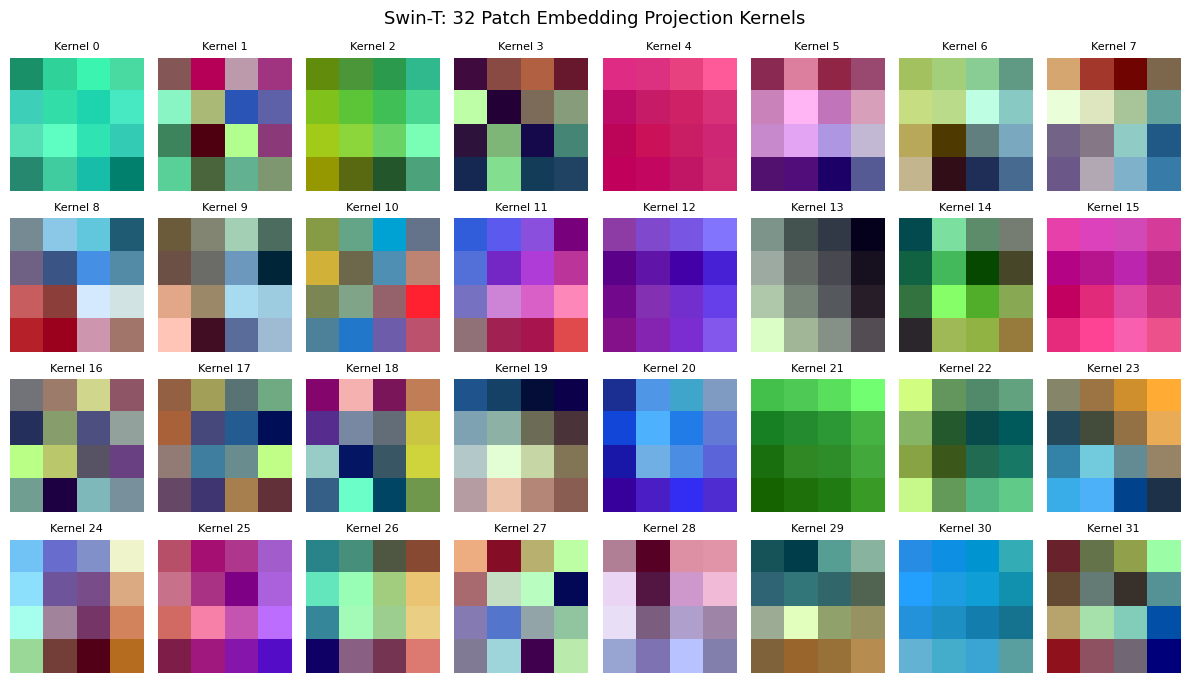

Patch embedding weights: (96, 3, 4, 4)


In [17]:
# 7.13.2 — Trực quan hóa 32 bộ lọc Patch Embedding: tensor [96, 3, 4, 4]
# TorchVision Swin-T: features[0][0] là Conv2d(3,96,kernel_size=4,stride=4)
patch_conv = my_model.features[0][0]
kernels = patch_conv.weight.detach().float().cpu().numpy()
assert kernels.ndim == 4 and kernels.shape[1] == 3
fig, axes = plt.subplots(4, 8, figsize=(12, 7))
for i, ax in enumerate(axes.flat):
    v = kernels[i].transpose(1, 2, 0)
    v = (v - v.min()) / (v.max() - v.min() + 1e-8)
    ax.imshow(v, interpolation='nearest')
    ax.set_title(f'Kernel {i}', fontsize=8)
    ax.axis('off')
fig.suptitle('Swin-T: 32 Patch Embedding Projection Kernels', fontsize=13)
plt.tight_layout()
plt.savefig(VIS_DIR/'patch_embedding_filters.png', dpi=200, bbox_inches='tight')
plt.show()
print('Patch embedding weights:', kernels.shape)

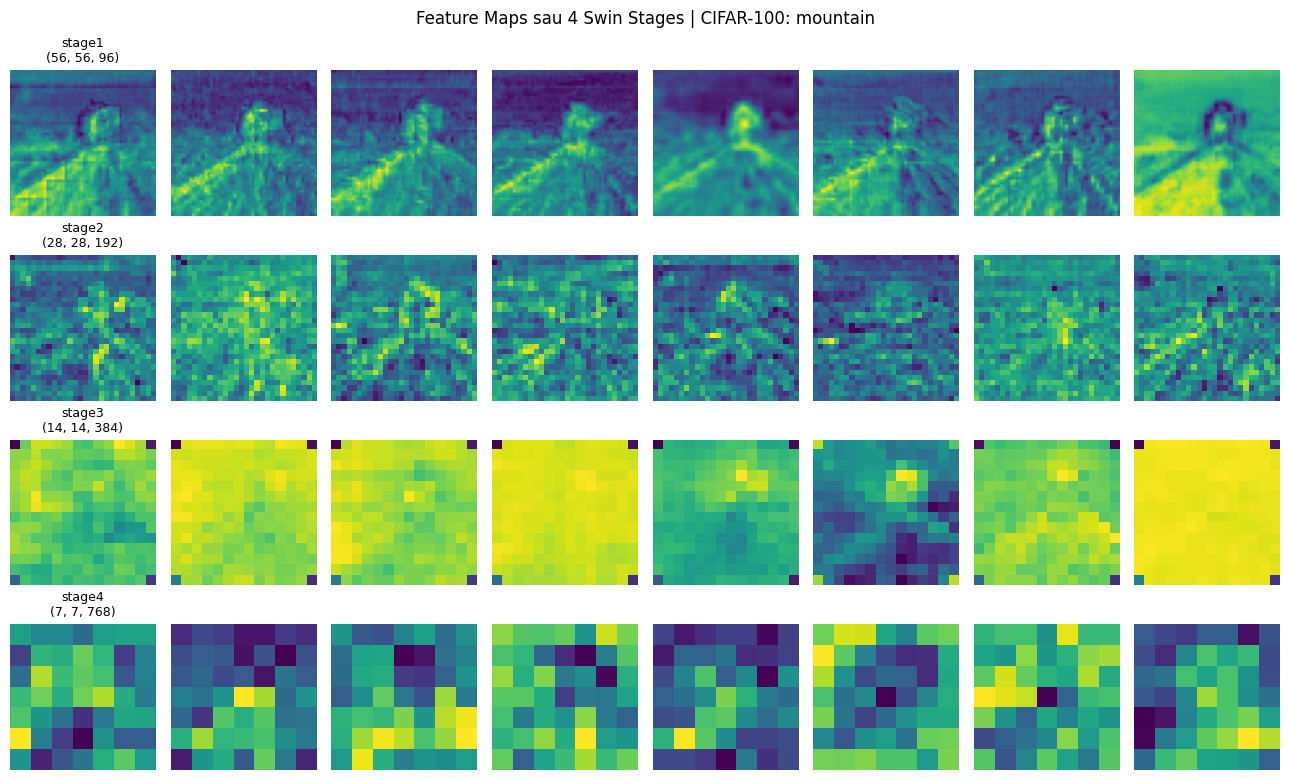

Kích thước activation: {'stage1': (1, 56, 56, 96), 'stage2': (1, 28, 28, 192), 'stage3': (1, 14, 14, 384), 'stage4': (1, 7, 7, 768)}


In [18]:
# 7.13.3 — Hook trích activation 4 stage; Swin TorchVision dùng tensor NHWC ở features
# Một ảnh đại diện lấy từ tập TEST; không thay đổi trạng thái mô hình.
stage_layers = {'stage1': my_model.features[1],
                'stage2': my_model.features[3],
                'stage3': my_model.features[5],
                'stage4': my_model.features[7]}
activations = {}
hooks = []
def capture(name):
    def fn(module, inputs, output):
        activations[name] = output.detach().float().cpu()
    return fn
for name, layer in stage_layers.items():
    hooks.append(layer.register_forward_hook(capture(name)))

sample_image, sample_label = test_ds[0]
with torch.inference_mode():
    _ = my_model(sample_image.unsqueeze(0).to(DEVICE))
for hook in hooks:
    hook.remove()

fig, axes = plt.subplots(4, 8, figsize=(13, 8))
for row, (name, tensor) in enumerate(activations.items()):
    # shape [B,H,W,C]; vẽ 8 channel đầu, scale riêng từng map
    maps = tensor[0].numpy()
    for col in range(8):
        axes[row, col].imshow(maps[:, :, col], cmap='viridis')
        axes[row, col].axis('off')
        if col == 0: axes[row, col].set_title(f'{name}\n{maps.shape}', fontsize=9)
fig.suptitle('Feature Maps sau 4 Swin Stages | CIFAR-100: '+str(class_names[sample_label]))
plt.tight_layout()
plt.savefig(VIS_DIR/'swin_stage_feature_maps.png', dpi=200, bbox_inches='tight')
plt.show()
print('Kích thước activation:', {k: tuple(v.shape) for k, v in activations.items()})

In [19]:
# Swin-T: trích vector 768 chiều trên đủ 10.000 ảnh, 100 lớp CIFAR-100.
SELECTED_CLASS_IDS = list(range(100))
indices = list(range(len(test_ds)))
assert len(indices) == 10000
analysis_loader = DataLoader(Subset(test_ds, indices),batch_size=16,shuffle=False,num_workers=0)
feature_model = copy.deepcopy(my_model)
feature_model.head = nn.Identity()
feature_model.eval()
vectors, labels = [], []
with torch.inference_mode():
    for x, yy in tqdm(analysis_loader, desc='Swin 100 classes feature extraction', mininterval=8):
        with torch.autocast(device_type='cuda', enabled=DEVICE.type=='cuda'):
            feat = feature_model(x.to(DEVICE))
        vectors.append(feat.float().cpu().numpy())
        labels.extend(yy.tolist())
X=np.concatenate(vectors,axis=0).astype(np.float32)
y=np.asarray(labels,dtype=np.int64)
assert X.shape==(10000,768),X.shape
np.save(VIS_DIR/'swin_features_10000x768.npy',X)
np.save(VIS_DIR/'sample_test_indices.npy',np.asarray(indices))
pd.DataFrame({'test_index':indices,'class_id':y,
              'class_name':[class_names[k] for k in y]}).to_csv(VIS_DIR/'feature_sample_manifest.csv',index=False)
del feature_model
if torch.cuda.is_available(): torch.cuda.empty_cache()
print('Đã trích toàn bộ:',X.shape)

Swin 100 classes feature extraction:   0%|          | 0/625 [00:00<?, ?it/s]

Đã trích toàn bộ: (10000, 768)


In [20]:
# Giảm chiều trên toàn bộ 10.000 ảnh, 100 lớp; cùng thứ tự TEST giữa CNN và Swin-T.
# Chuẩn hóa từng chiều trước PCA/t-SNE, cố định SEED=42 để có thể tái lập.
Z = StandardScaler().fit_transform(X).astype(np.float32)
P3 = PCA(n_components=3, random_state=SEED).fit_transform(Z)
P2 = P3[:, :2]
pca_variances = PCA(n_components=3, random_state=SEED).fit(Z).explained_variance_ratio_
# PCA 50 thành phần trước t-SNE giúp giảm thời gian và nhiễu
Z50 = PCA(n_components=50, random_state=SEED).fit_transform(Z)
tsne_args = dict(perplexity=30, learning_rate='auto', init='pca',
                 random_state=SEED, max_iter=750, method='barnes_hut')
T2 = TSNE(n_components=2, **tsne_args).fit_transform(Z50)
T3 = TSNE(n_components=3, **tsne_args).fit_transform(Z50)
# Silhouette trên 2.000 ảnh cân bằng (20/lớp): tránh ma trận khoảng cách quá lớn.
rng = np.random.default_rng(SEED)
sil_indices = np.sort(np.concatenate([rng.choice(np.where(y == c)[0], 20, replace=False)
                                     for c in range(100)]))
sil = float(silhouette_score(Z[sil_indices], y[sil_indices], metric='euclidean'))

np.savez_compressed(VIS_DIR/'all100_reduced_coordinates.npz',pca2=P2,pca3=P3,tsne2=T2,tsne3=T3,labels=y,indices=np.asarray(indices))
metrics={'samples':len(y),'classes':len(np.unique(y)),'feature_dim':X.shape[1],
 'silhouette_2000_balanced_samples':sil,'pca2_explained_variance':float(pca_variances[:2].sum()),
 'pca3_explained_variance':float(pca_variances.sum()),'tsne_perplexity':30,'tsne_max_iter':750,
 'silhouette_sample_count':len(sil_indices),'class_ids':SELECTED_CLASS_IDS}
with open(VIS_DIR/'feature_metrics_100classes.json','w',encoding='utf-8') as f:json.dump(metrics,f,ensure_ascii=False,indent=2)
pd.DataFrame({'class_id':range(100),'class_name':class_names}).to_csv(VIS_DIR/'cifar100_class_legend.csv',index=False)
print('100 lớp:',metrics)

100 lớp: {'samples': 10000, 'classes': 100, 'feature_dim': 768, 'silhouette_2000_balanced_samples': 0.04748833552002907, 'pca2_explained_variance': 0.06148931384086609, 'pca3_explained_variance': 0.08555512875318527, 'tsne_perplexity': 30, 'tsne_max_iter': 750, 'silhouette_sample_count': 2000, 'class_ids': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99]}


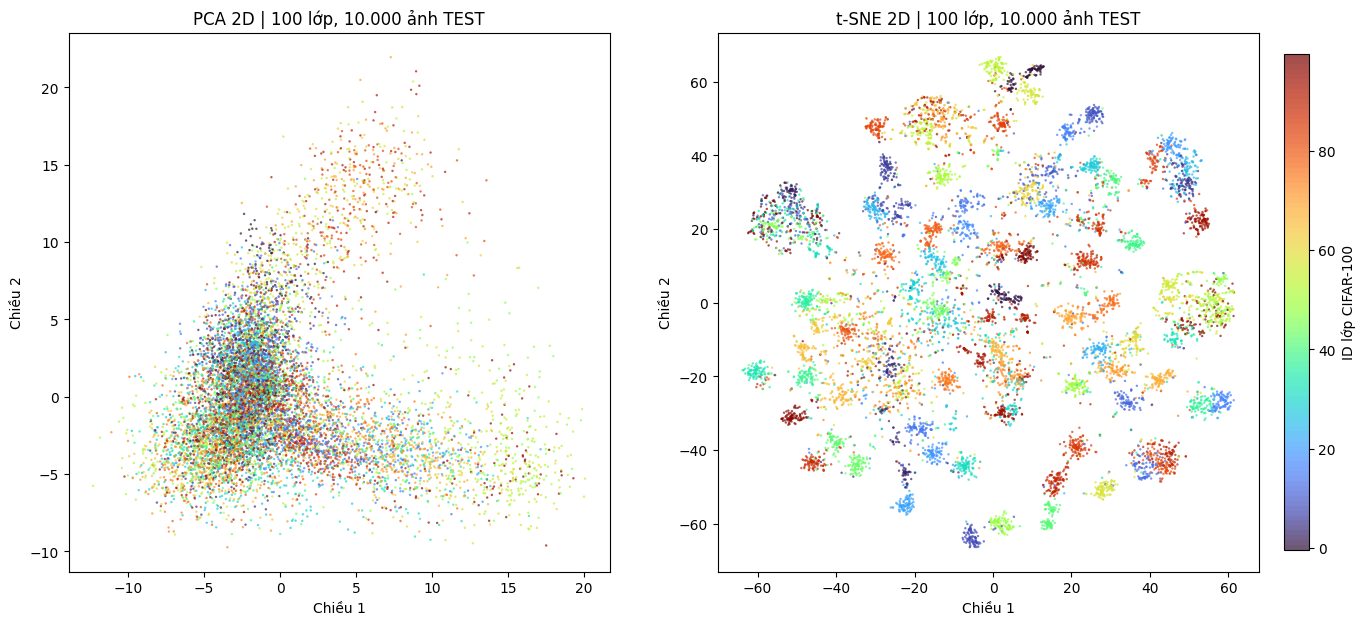

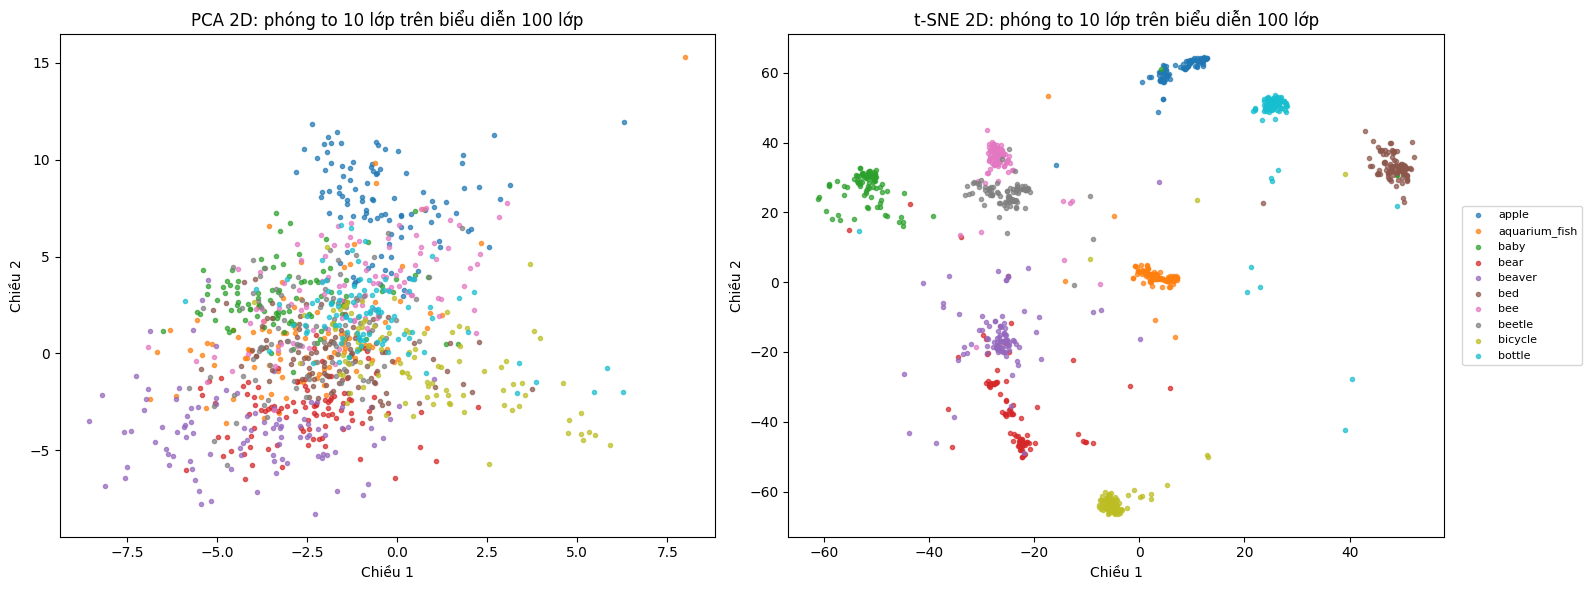

In [21]:
# PCA/t-SNE 2D: 100 lớp trên 10.000 ảnh TEST.
# Màu mã hóa class_id 0..99. Bảng tên lớp được lưu ở CSV, không nhồi 100 nhãn vào hình.
from matplotlib.colors import BoundaryNorm
palette = plt.get_cmap('turbo', 100)
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, (xy, method) in zip(axes, [(P2, 'PCA 2D'), (T2, 't-SNE 2D')]):
    dots = ax.scatter(xy[:, 0], xy[:, 1], c=y, s=3, cmap=palette,
                      vmin=-0.5, vmax=99.5, alpha=0.7, linewidths=0)
    ax.set_title(method + ' | 100 lớp, 10.000 ảnh TEST')
    ax.set_xlabel('Chiều 1'); ax.set_ylabel('Chiều 2')
fig.colorbar(dots, ax=list(axes), label='ID lớp CIFAR-100', fraction=.02, pad=.02)
fig.savefig(VIS_DIR/'all100_pca_tsne_2d.png', dpi=200, bbox_inches='tight')
plt.show()

# Phóng to 10 lớp đầu từ tọa độ được tính trên toàn bộ 100 lớp.
# Các lớp còn lại ẩn khỏi hình này, nhưng không bị loại khỏi PCA/t-SNE.
mask = np.isin(y, np.arange(10))
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
c10 = plt.get_cmap('tab10')
for ax, (xy, method) in zip(axes, [(P2, 'PCA 2D'), (T2, 't-SNE 2D')]):
    for k in range(10):
        m = y == k
        ax.scatter(xy[m, 0], xy[m, 1], color=c10(k), s=9, alpha=.7,
                   label=class_names[k])
    ax.set_title(method + ': phóng to 10 lớp trên biểu diễn 100 lớp')
    ax.set_xlabel('Chiều 1'); ax.set_ylabel('Chiều 2')
axes[1].legend(loc='center left', bbox_to_anchor=(1.02,.5), fontsize=8)
fig.tight_layout()
fig.savefig(VIS_DIR/'detail10_pca_tsne_2d.png',dpi=200,bbox_inches='tight')
plt.show()

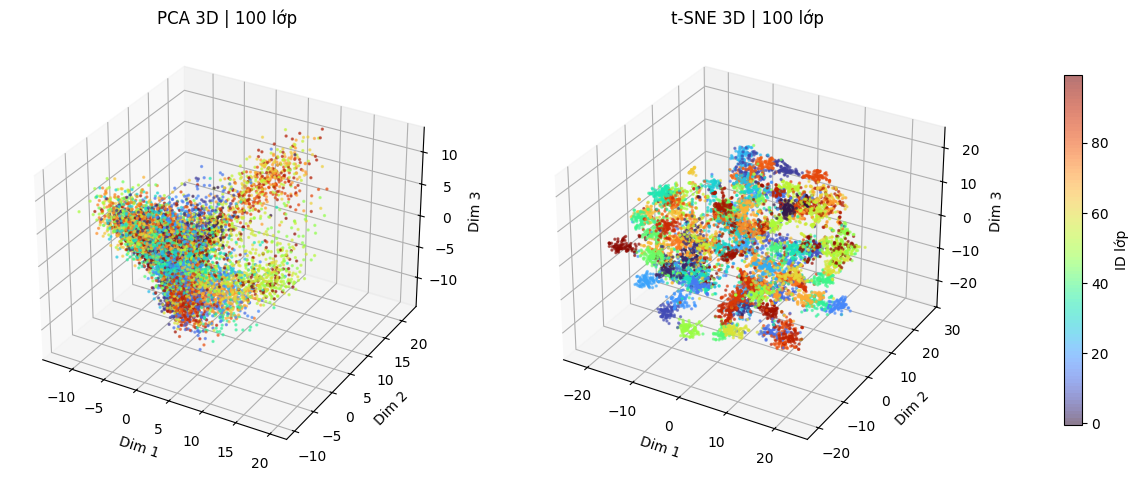

In [22]:
# PCA/t-SNE 3D của toàn bộ 100 lớp.
fig = plt.figure(figsize=(16, 7))
for j, (xyz, method) in enumerate([(P3, 'PCA 3D'), (T3, 't-SNE 3D')], 1):
    ax = fig.add_subplot(1, 2, j, projection='3d')
    dots = ax.scatter(xyz[:,0], xyz[:,1], xyz[:,2], c=y,
                      s=2, alpha=.55, cmap=palette, vmin=-.5, vmax=99.5)
    ax.set_title(method + ' | 100 lớp')
    ax.set_xlabel('Dim 1'); ax.set_ylabel('Dim 2'); ax.set_zlabel('Dim 3')
fig.colorbar(dots, ax=fig.axes, shrink=.65, pad=.08, label='ID lớp')
fig.savefig(VIS_DIR/'all100_pca_tsne_3d.png',dpi=200,bbox_inches='tight')
plt.show()

In [23]:
# Đóng gói kết quả visualization, KHÔNG nén checkpoint lớn để tránh ZIP quá nặng
VIS_DIR=OUTPUT_DIR/'feature_analysis'
archive=Path('/kaggle/working/swin_feature_visualization.zip')
with zipfile.ZipFile(archive,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for f in VIS_DIR.rglob('*'):
        if f.is_file(): z.write(f,arcname=f.relative_to(OUTPUT_DIR))
print('ZIP phân tích:',archive)

ZIP phân tích: /kaggle/working/swin_feature_visualization.zip
